In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
df = pd.read_csv('/Users/udaykumarreddy/Desktop/Advanced Data Science Technique/Linear Regression/playgolf_data.csv')

In [3]:
df

,Outlook,Temperature,Humidity,Wind,PlayGolf
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rainy,Mild,High,Weak,Yes
4,Rainy,Cool,Normal,Weak,Yes
5,Rainy,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rainy,Mild,Normal,Weak,Yes


In [4]:
df.shape

(14, 5)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Outlook      14 non-null     str  
 1   Temperature  14 non-null     str  
 2   Humidity     14 non-null     str  
 3   Wind         14 non-null     str  
 4   PlayGolf     14 non-null     str  
dtypes: str(5)
memory usage: 1001.0 bytes


In [8]:
df.head()

,Outlook,Temperature,Humidity,Wind,PlayGolf
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rainy,Mild,High,Weak,Yes
4,Rainy,Cool,Normal,Weak,Yes


In [9]:
df.describe(include="all")

,Outlook,Temperature,Humidity,Wind,PlayGolf
count,14,14,14,14,14
unique,3,3,2,2,2
top,Sunny,Mild,High,Weak,Yes
freq,5,6,7,8,9


In [11]:
print(df.isnull().sum())

Outlook        0
Temperature    0
Humidity       0
Wind           0
PlayGolf       0
dtype: int64


In [12]:
print(df.dtypes)

Outlook        str
Temperature    str
Humidity       str
Wind           str
PlayGolf       str
dtype: object


In [13]:
print(df.duplicated().sum())

0


In [14]:
numerical_variables = df.select_dtypes(include=["int64", "float64"]).columns
categorical_variables = df.select_dtypes(include=["object", "category"]).columns

print("Numerical Variables:")
print(list(numerical_variables))

print("\nCategorical Variables:")
print(list(categorical_variables))

Numerical Variables:
[]

Categorical Variables:
['Outlook', 'Temperature', 'Humidity', 'Wind', 'PlayGolf']


/var/folders/9h/lyx20x8s4496mkq5ddbsq91w0000gn/T/ipykernel_15206/3654047098.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_variables = df.select_dtypes(include=["object", "category"]).columns


In [15]:
df = df.drop_duplicates().copy()

print("Duplicate rows removed.")
print("Dataset shape:", df.shape)

Duplicate rows removed.
Dataset shape: (14, 5)


In [16]:
df = df.dropna().copy()

print("Missing values:")
print(df.isnull().sum())

Missing values:
Outlook        0
Temperature    0
Humidity       0
Wind           0
PlayGolf       0
dtype: int64


In [17]:
le = LabelEncoder()

for column in df.columns:
    df[column] = le.fit_transform(df[column])

df.head()

,Outlook,Temperature,Humidity,Wind,PlayGolf
0,2,1,0,1,0
1,2,1,0,0,0
2,0,1,0,1,1
3,1,2,0,1,1
4,1,0,1,1,1


In [18]:
X = df.drop(columns=["PlayGolf"])

y = df["PlayGolf"]

In [19]:
print("Selected Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Selected Features:
['Outlook', 'Temperature', 'Humidity', 'Wind']

Target Variable:
PlayGolf

Feature Shape: (14, 4)
Target Shape: (14,)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [21]:
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Percentage:", len(X_train) / len(X) * 100)
print("Testing Percentage:", len(X_test) / len(X) * 100)

Training Data Shape: (11, 4)
Testing Data Shape: (3, 4)
Training Percentage: 78.57142857142857
Testing Percentage: 21.428571428571427


In [22]:
model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [23]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.tolist())

print("\nPredicted Values:")
print(y_pred.tolist())

Actual Values:
[0, 1, 1]

Predicted Values:
[0, 1, 1]


In [24]:
accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", round(accuracy * 100, 2), "%")

Decision Tree Accuracy: 100.0 %


In [25]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1 0]
 [0 2]]


In [26]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

comparison["Correct"] = comparison["Actual"] == comparison["Predicted"]

display(comparison)

,Actual,Predicted,Correct
7,0,0,True
11,1,1,True
8,1,1,True


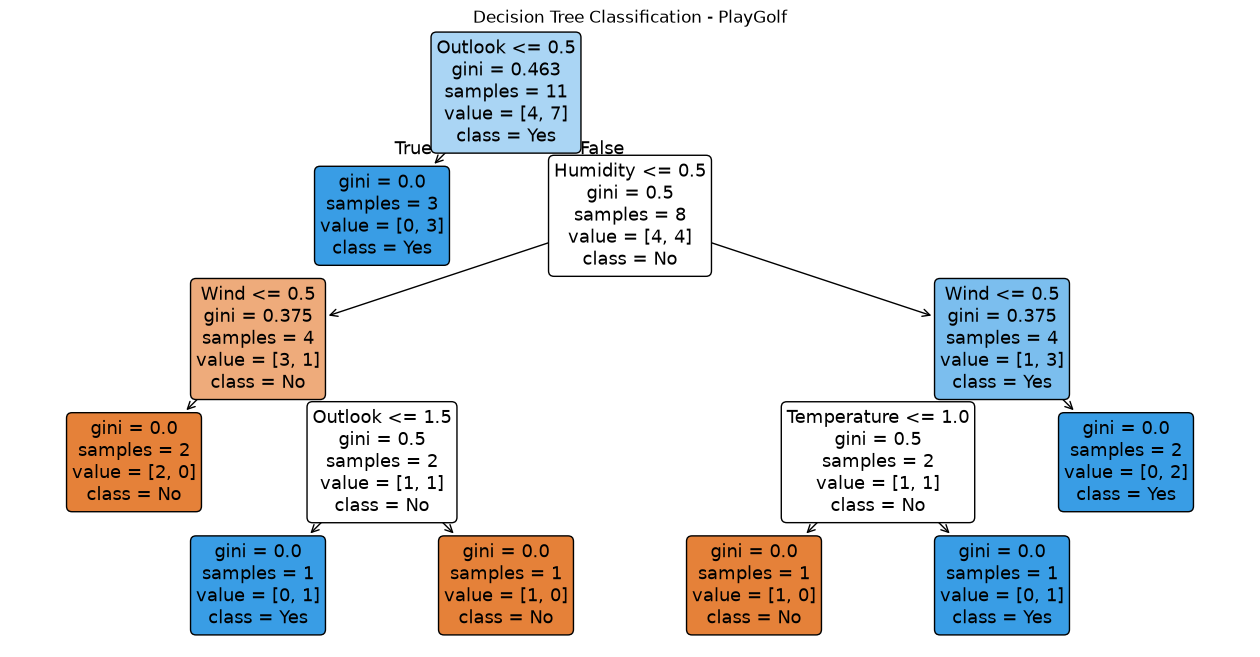

In [27]:
plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree Classification - PlayGolf")
plt.show()